# Options: the greeks in pictures, then how to hedge them

The book so far was hedged with futures only, so it could only fix the delta. This notebook
starts from one option on one Brent future: first what its greeks are (part A), then how a
desk hedges them (part B).

Two rules to know by heart ([docs/Options.md](../docs/Options.md)):

1. **Call or put sets the sign of the delta.** Long call +, long put −, short call −, short put +.
2. **Bought or sold sets gamma, vega and theta.** Bought: long gamma, long vega, pays theta.
   Sold: the opposite.

**A. Understand**

1. One curve holds every greek
2. Vega and theta: change the vol, change the time
3. The four positions, all greeks at once
4. Every strike at once: surfaces
5. I want … → I do …, checked

**B. Hedge**

6. The delta: futures, opposite sign
7. Why the hedge has to be redone: gamma
8. Removing the gamma: an option first, then futures
9. In real life: lots of 1,000 bbl

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import QuantLib as ql

from cmdty import MarketData, Pricer, Quote
from cmdty.instruments import VanillaOption
from cmdty.models.black76 import analytic_greeks, expected_payoff
from cmdty.plotting import MUTED, SERIES, plot_delta, plot_gamma, plot_theta, plot_value, plot_vega, titles, use_style
from cmdty.strategies import option, position_greeks, straddle

use_style()

def market_at(f: float, vol: float | None = None, date: ql.Date | None = None) -> MarketData:
    """Same market, only the future price, the vol or the date changes (default: VOL, TODAY)."""
    date = TODAY if date is None else date
    vol = VOL if vol is None else vol
    return MarketData(today=date, rate=0.04, quotes={U: Quote(f, vol)})


def opt(kind: str, strike: float, qty: float = 1.0, expiry: ql.Date | None = None) -> VanillaOption:
    """One vanilla option on the Brent future, qty in bbl, negative = sold (default expiry: EXPIRY)."""
    return VanillaOption(underlying=U, contract=CONTRACT, expiry=EXPIRY if expiry is None else expiry, strike=strike,
                         option_type=kind, quantity=qty)


def value(o: VanillaOption, f: float, vol: float | None = None, date: ql.Date | None = None) -> float:
    """Position value in $ (Black-76, QuantLib)."""
    return o.quantity * expected_payoff(o, market_at(f, vol, date))


def greeks(o: VanillaOption, f: float) -> dict:
    """Position greeks at future price f: delta (bbl), gamma, vega ($/vol pt), theta ($/day)."""
    g = analytic_greeks(o, market_at(f))
    theta = value(o, f, date=TODAY + 1) - value(o, f)
    return dict(delta=o.quantity * g.delta, gamma=o.quantity * g.gamma,
                vega=o.quantity * g.vega, theta=theta)


def payoff(o: VanillaOption, f):
    """Position value at expiry."""
    phi = 1 if o.option_type.value == "call" else -1
    return o.quantity * np.maximum(phi * (np.asarray(f) - o.strike), 0)

Vanilla options, priced with QuantLib's Black-76 (`ql.blackFormula`, greeks from
`ql.BlackCalculator`). Values are undiscounted, so they read directly as $. Brent future at
75 $, vol 32 %, 3 months to expiry.

# A. Understand

## 1. One curve holds every greek

A long call, strike 83. At expiry its value is a broken line: 0 below the strike, then
1 $ per $ above. Before expiry the same line is **rounded**. Each curve below is the **slope**
of the one above it.

In [2]:
# Scenario setup 

TODAY = ql.Date(25, 11, 2026)
U = "BRENT" # underlying 
CONTRACT = "2027-03" # trading period
EXPIRY = ql.Date(25, 2, 2027) # expirity date
F0 = 75.0 # price of the future TODAY
VOL = 0.32 # implied volatility of the option 
K = 83.0 # Strike price of the option

# option values asof TODAY  

call_83 = opt("call", K)
V0 = value(call_83, F0) # value of the option today.
d0 = greeks(call_83, F0)["delta"] # delta of the option today
g0 = greeks(call_83, F0)["gamma"] # gamma of the option today
v0 = greeks(call_83, F0)["vega"] # vega of the option today
t0 = greeks(call_83, F0)["theta"] # theta of the option today

print("Today:")
print(" => value of the future: ", F0)
print(" => value of the option: ", V0)
print(" => value of the delta: ", d0)
print(" => value of the gamma: ", g0)
print(" => value of the vega: ", v0)
print(" => value of the theta: ", t0)

# creation of the X-price axis range

F_wide = np.linspace(45, 125, 321)  # wide: shows both ends (delta 0 and 1)

# greeks values for the differents future prices. 

V = np.array([value(call_83, f) for f in F_wide]) # value of the option for each prices of the future in F_wide
D = np.array([greeks(call_83, f)["delta"] for f in F_wide]) # delta for each prices of the future in F_wide 
G = np.array([greeks(call_83, f)["gamma"] for f in F_wide]) # gamma for each prices of the future in F_wide

Today:
 => value of the future:  75.0
 => value of the option:  2.029138538478012
 => value of the delta:  0.29097531277055744
 => value of the gamma:  0.028453507047152493
 => value of the vega:  0.1290931716988617
 => value of the theta:  -0.022488193360356235


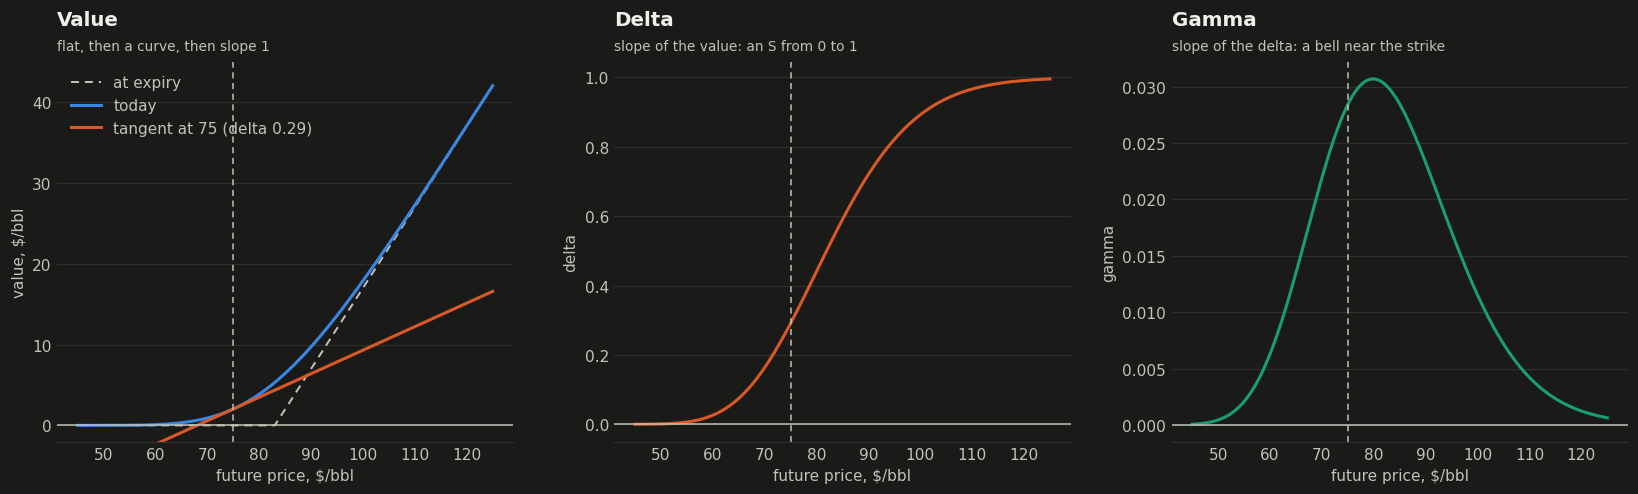

In [3]:
payoff_at_expiry = payoff(call_83, F_wide) # Payoff at expiry
delta_approx = V0 + d0 * (F_wide - F0) # the gap between the curve and this line is what remains after the futures hedge: the gamma

value_curves = {
    "today": V,
    f"tangent at 75 (delta {d0:.2f})": delta_approx,
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
plot_value(F_wide, value_curves, f0=F0, payoff=payoff_at_expiry, subtitle="flat, then a curve, then slope 1",
           ax=axes[0])
plot_delta(F_wide, D, f0=F0, subtitle="slope of the value: an S from 0 to 1", ax=axes[1])
plot_gamma(F_wide, G, f0=F0, subtitle="slope of the delta: a bell near the strike", ax=axes[2])
axes[0].set(ylim=(-2, 45))
fig.tight_layout(w_pad=2)
plt.show()

- **Delta = slope.** 0.29 at 75 $: the call gains 0.29 $ when the future gains 1 $.
- **Gamma = how fast the slope changes.** Near the strike the option hesitates between
  finishing in or out of the money, so each dollar changes the delta a lot. Far away the
  answer is decided (delta 0 or 1) and the gamma falls to 0.
- Near 75 the value looks like x²; further right it becomes a straight line of slope 1: the
  call then moves like a future.

## 2. Vega and theta: change the vol, change the time

Same call (strike 83), on `F` instead of `F_wide`: zoomed around 75 $, where vega and theta matter. The future price is no longer what moves: on the left the
vol changes, on the right time passes.

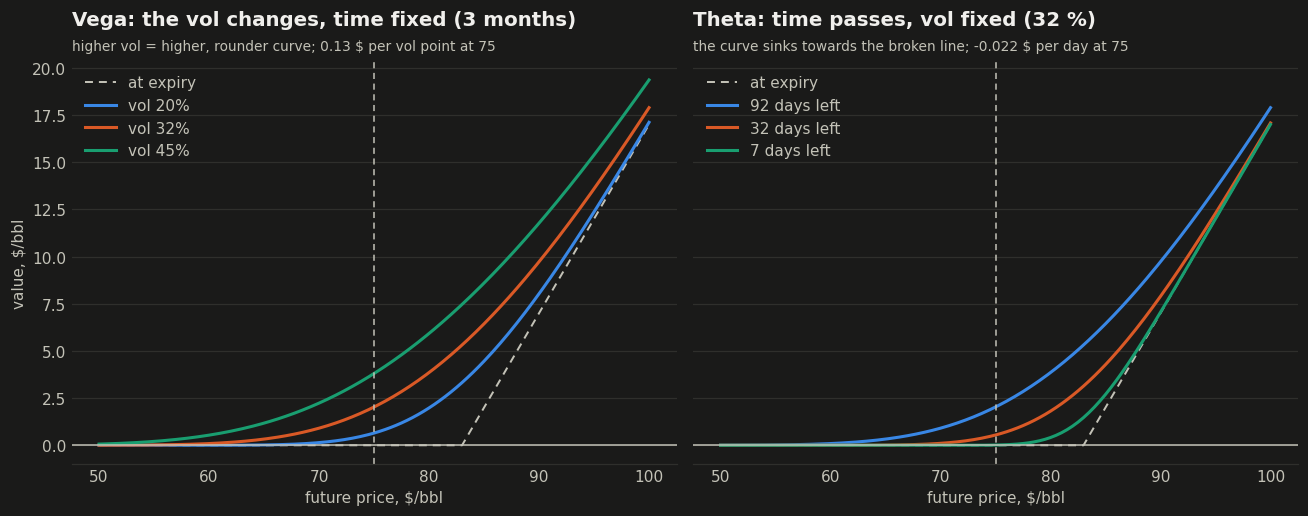

In [4]:
F = np.linspace(50, 100, 201)  # zoom around F0

by_vol = {f"vol {v:.0%}": [value(call_83, f, vol=v) for f in F] for v in (0.20, 0.32, 0.45)}
by_date = {f"{EXPIRY - (TODAY + d)} days left": [value(call_83, f, date=TODAY + d) for f in F]
           for d in (0, 60, 85)}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
plot_value(F, by_vol, f0=F0, payoff=payoff(call_83, F), ax=axes[0],
           title="Vega: the vol changes, time fixed (3 months)",
           subtitle=f"higher vol = higher, rounder curve; {v0:.2f} $ per vol point at 75")
plot_value(F, by_date, f0=F0, payoff=payoff(call_83, F), ax=axes[1],
           title="Theta: time passes, vol fixed (32 %)",
           subtitle=f"the curve sinks towards the broken line; {t0:.3f} $ per day at 75")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

- **Vega** = the vertical gap between two vol curves, for 1 vol point.
- **Theta** = the vertical gap between two dates, for 1 day. It speeds up near expiry.
- The two pictures look alike, and that is no accident: in Black-76 vol and time only enter
  as **σ × √T**. A 3-month option at 32 % has the same curve as a 1-month option at about
  55 %. What tells them apart is the cause: time only goes one way and is certain (theta),
  the implied vol goes up or down with the market (vega). In a P&L explain, the date moved →
  theta; the quoted vol moved → vega.

The same √T explains how they change with maturity. Here an **at-the-money** call (strike = 75):
for an out-of-the-money one like the 83, a very short option has almost no gamma left, since it
will most likely expire worthless.

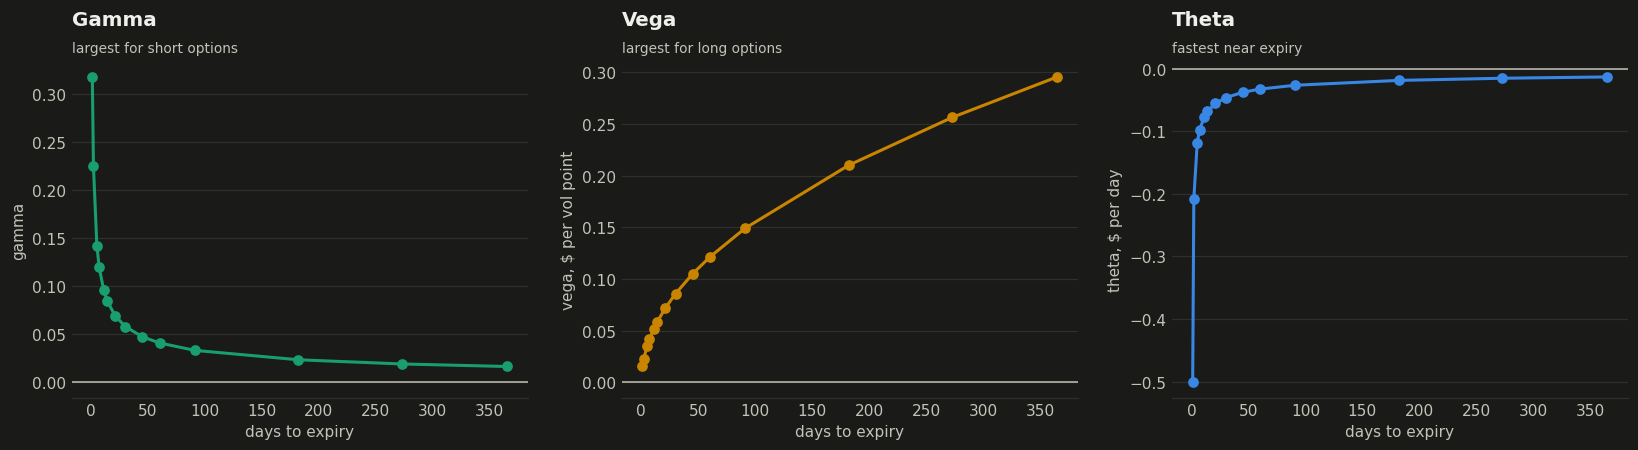

In [8]:
DAYS_EXPIRITY = [1, 2, 5, 7, 11, 14, 21, 30, 45, 60, 91, 182, 273, 365]

rows = []
for d in DAYS_EXPIRITY:
    o = opt("call", F0, expiry=TODAY + d)  # at the money: strike = F0
    g = greeks(o, F0)
    rows.append(dict(days=d, gamma=g["gamma"], vega=g["vega"], theta=g["theta"]))

term = pd.DataFrame(rows).set_index("days")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
plot_gamma(term.index, term["gamma"], subtitle="largest for short options", xlabel="days to expiry",
           marker="o", ax=axes[0])
plot_vega(term.index, term["vega"], subtitle="largest for long options", xlabel="days to expiry",
          marker="o", ax=axes[1])
plot_theta(term.index, term["theta"], subtitle="fastest near expiry", xlabel="days to expiry",
           marker="o", ax=axes[2])
fig.tight_layout(w_pad=2)
plt.show()

**Short-dated options are the gamma tool, long-dated ones the vega tool.** That is why a desk
uses two maturities to hedge gamma and vega separately.

## 3. The four positions, all greeks at once

Strike 75 here (at the money), for two reasons:

1. Gamma, vega and theta are largest at the money: the gaps between the curves are easiest to see.
2. Call and put sit symmetrically around the future price, so the four columns compare directly.

1 bbl each. Columns: the four positions. Rows: value (dashed: at expiry), delta,
gamma, vega, theta. Blue = bought, orange = sold.

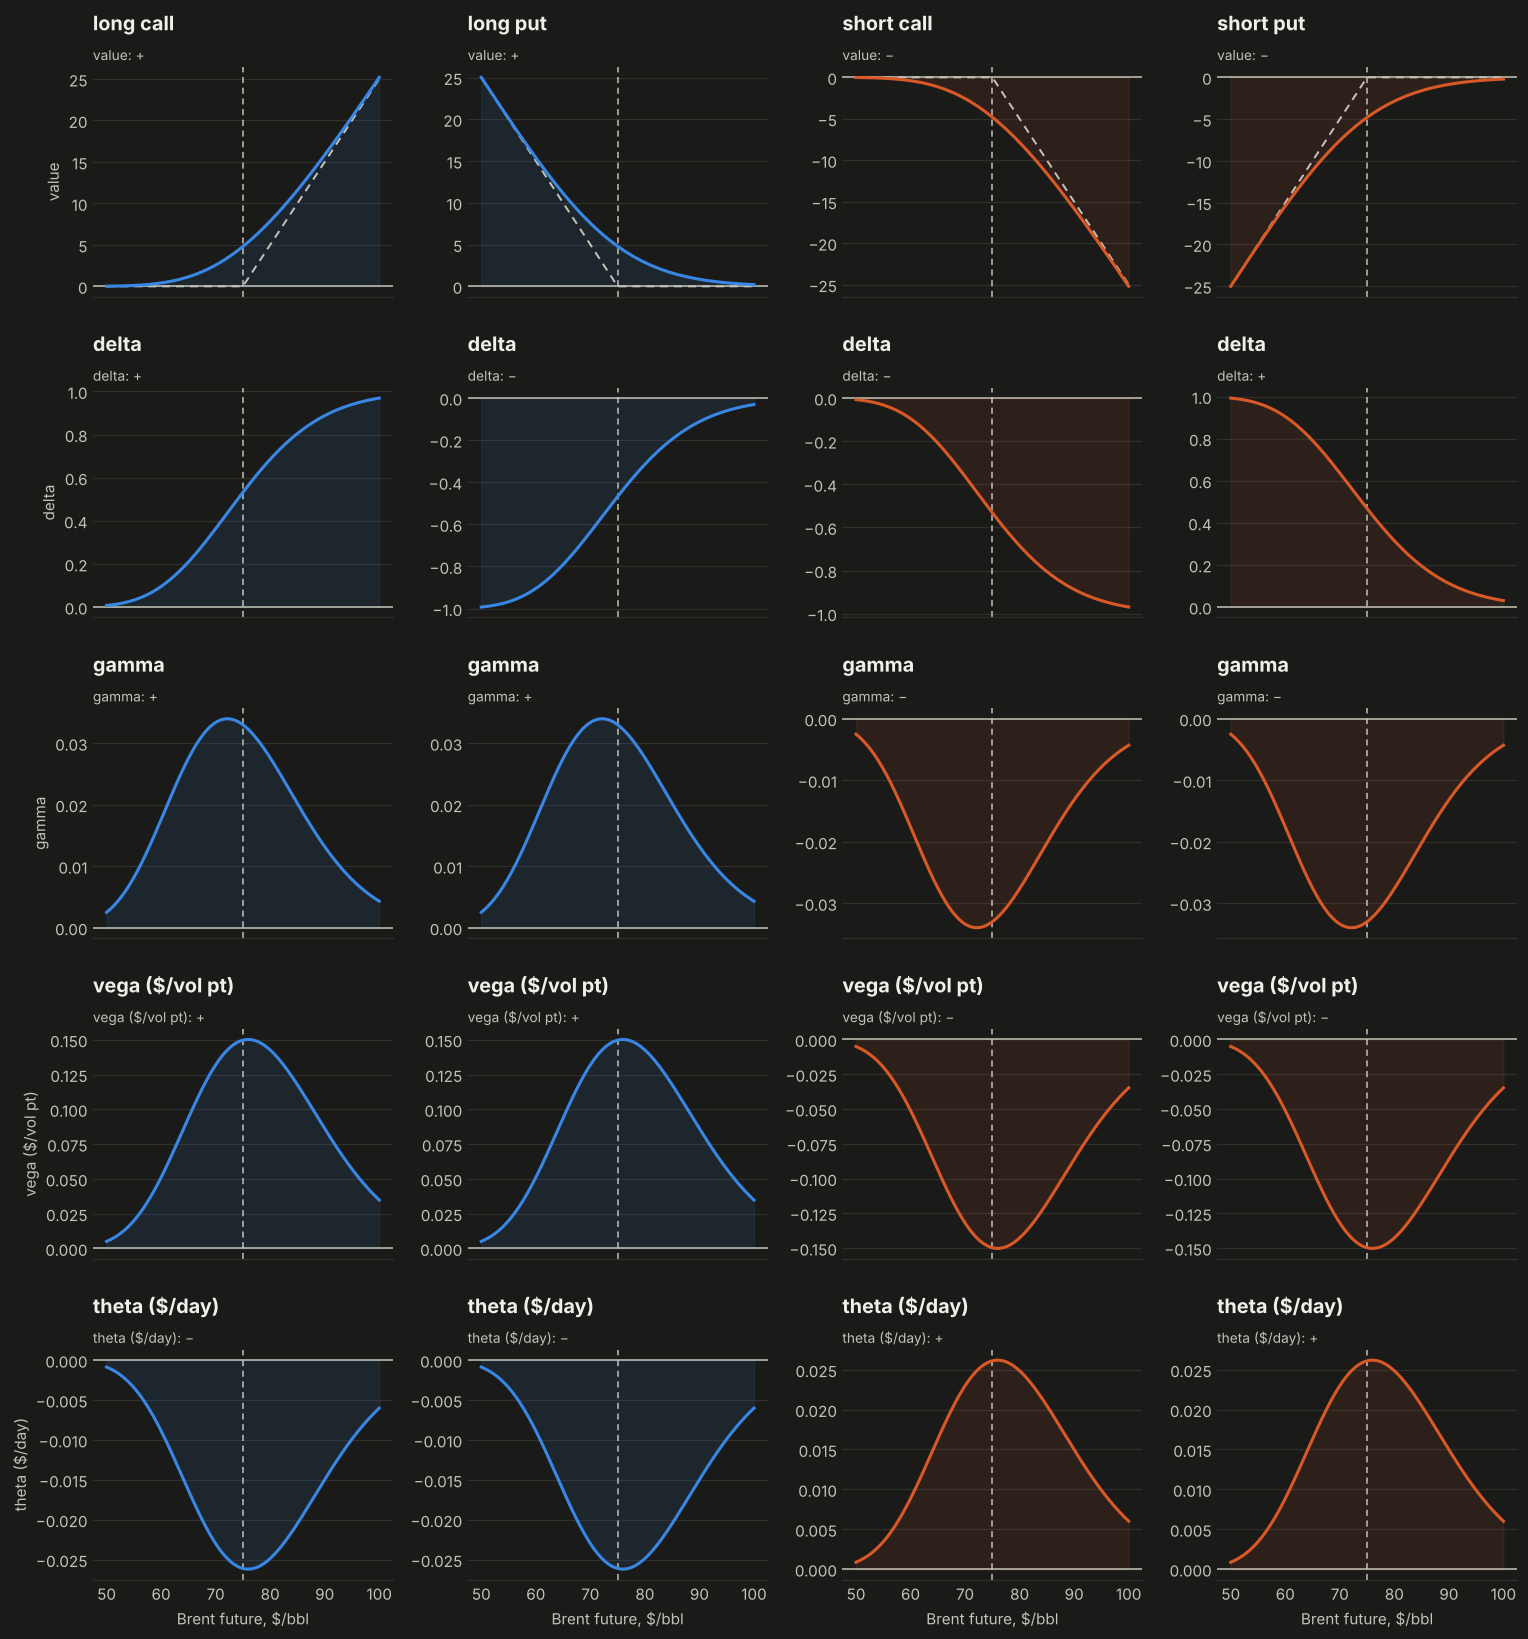

In [6]:
positions = {"long call": ("call", +1), "long put": ("put", +1),
             "short call": ("call", -1), "short put": ("put", -1)}
row_names = ["value", "delta", "gamma", "vega ($/vol pt)", "theta ($/day)"]

fig, axes = plt.subplots(5, 4, figsize=(14, 15), sharex=True)
for c, (name, (kind, q)) in enumerate(positions.items()):
    o = opt(kind, 75.0, q)
    color = SERIES[0] if q > 0 else SERIES[1]
    g = [greeks(o, f) for f in F]
    data = [np.array([value(o, f) for f in F])] + \
           [np.array([x[k] for x in g]) for k in ("delta", "gamma", "vega", "theta")]
    for r, y in enumerate(data):
        ax = axes[r, c]
        ax.set_axisbelow(True)
        ax.axhline(0, color=MUTED, linewidth=1)
        ax.axvline(F0, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
        if r == 0:
            ax.plot(F, payoff(o, F), color=MUTED, linewidth=1.3, linestyle=(0, (4, 3)))
        ax.plot(F, y, color=color, linewidth=2)
        ax.fill_between(F, y, 0, color=color, alpha=0.10)
        y0 = y[np.argmin(abs(F - F0))]
        sign = "+" if y0 > 1e-9 else "−"
        titles(ax, name if r == 0 else row_names[r], f"{row_names[r]}: {sign}")
        if c == 0:
            ax.set_ylabel(row_names[r])
for ax in axes[-1]:
    ax.set_xlabel("Brent future, $/bbl")
fig.tight_layout(h_pad=1.8)
plt.show()

The two rules, on one picture:

- **Delta** is the only row where **call and put differ**: long call and short put go up (+),
  long put and short call go down (−).
- **Gamma, vega, theta**: call and put are **identical**; only bought (blue) or sold
  (orange) matters. Gamma and vega are the same bell, + when bought; theta is the bell upside
  down: the buyer pays, the seller collects.
- A sold option is worth less than zero to its seller: a debt, paid for by the premium
  received at the start.
- All the bells peak **near the strike**: that is where everything happens.

The same signs, from the pricer's bump-and-reprice greeks (and a future for comparison):

In [7]:
market = market_at(F0)
pricer = Pricer(market=market)
EXP = "2027-02-25"
rows = {"future (long)": dict(delta=1.0, gamma=0.0, vega=0.0, theta=0.0)}
for name, (kind, q) in positions.items():
    g = position_greeks([option(name, U, CONTRACT, EXP, 75.0, kind, q)], pricer, U)
    rows[name] = dict(delta=g.delta, gamma=g.gamma, vega=g.vega, theta=g.theta)
table = pd.DataFrame(rows).T
signs = table.map(lambda x: "+" if x > 1e-9 else ("−" if x < -1e-9 else "0"))
pd.concat({"per bbl": table.round(4), "sign": signs}, axis=1)

per bbl                          sign                 
                delta   gamma    vega   theta delta gamma vega theta
future (long)  1.0000  0.0000  0.0000  0.0000     +     0    0     0
long call      0.5267  0.0327  0.1482 -0.0253     +     +    +     −
long put      -0.4633  0.0327  0.1482 -0.0253     −     +    +     −
short call    -0.5267 -0.0327 -0.1482  0.0253     −     −    −     +
short put      0.4633 -0.0327 -0.1482  0.0253     +     −    −     +

## 4. Every strike at once: surfaces

Section 1 is one strike. Doing it for every strike from 60 to 95 turns each curve into a
surface (axes: Brent, strike). Top row: P&L (value minus today's value, so every strike passes
through 0 at 75 $). Bottom row: the raw value. The futures hedge (`−delta(K)` futures, one per
strike) is explained in part B; it is here so the two rows can be compared.

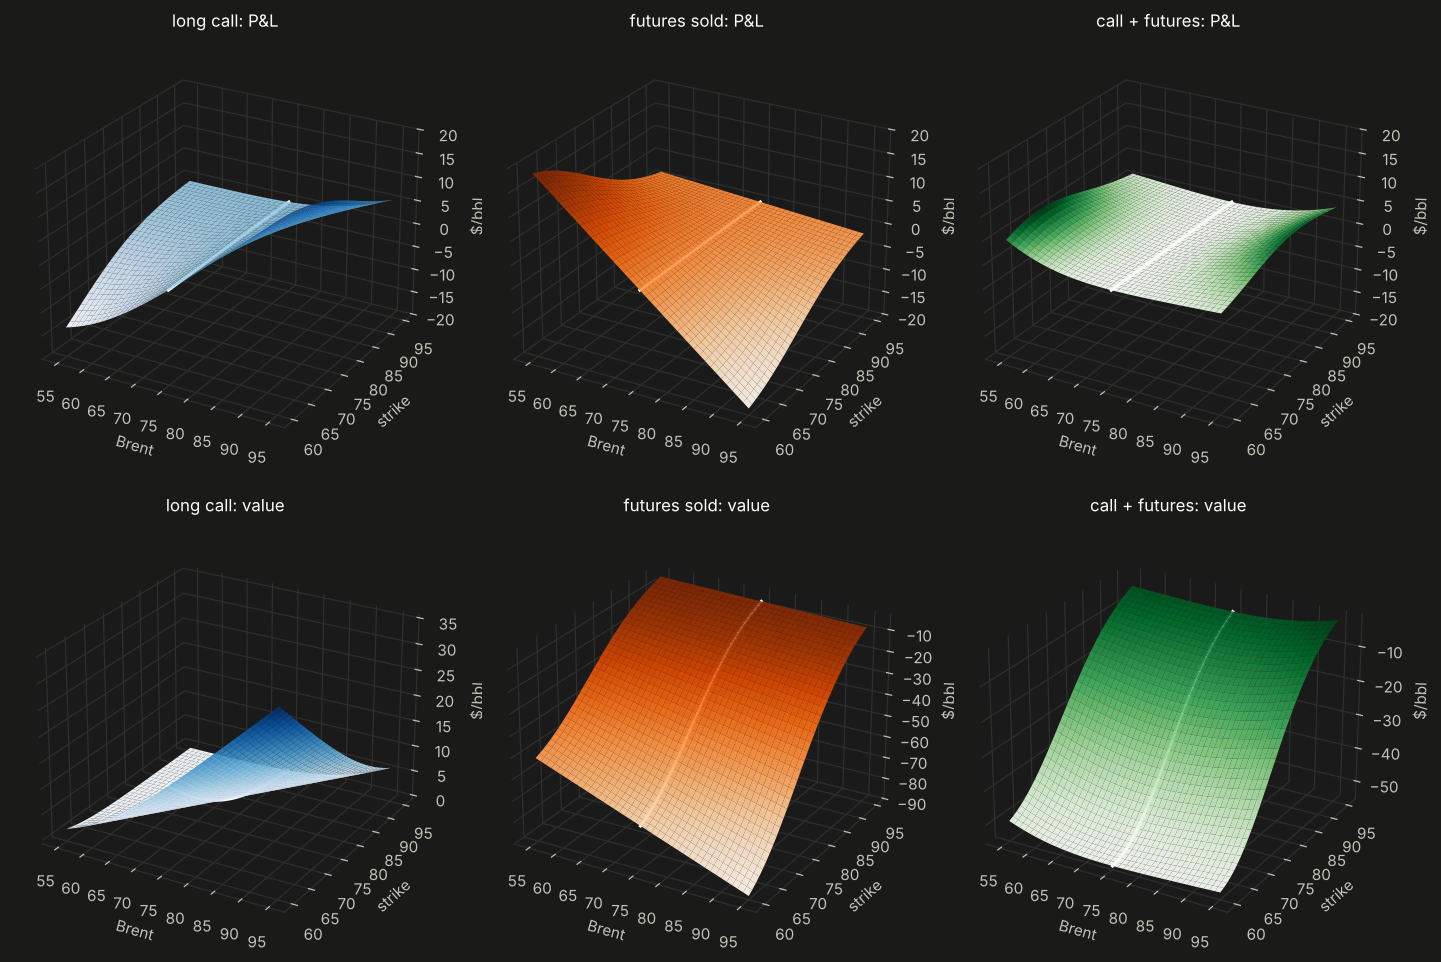

In [8]:
Fs, Ks = np.linspace(55, 95, 41), np.linspace(60, 95, 36)
FF, KK = np.meshgrid(Fs, Ks)
std = VOL * math.sqrt(opt("call", 75.0).day_counter.yearFraction(TODAY, EXPIRY))
V = np.vectorize(lambda f, k: ql.blackFormula(ql.Option.Call, k, f, std))(FF, KK)
V0 = np.vectorize(lambda k: ql.blackFormula(ql.Option.Call, k, F0, std))(KK)
DK = np.vectorize(lambda k: ql.BlackCalculator(
    ql.PlainVanillaPayoff(ql.Option.Call, k), F0, std, 1.0).deltaForward())(KK)

rows = [("P&L", [V - V0, -DK * (FF - F0), V - V0 - DK * (FF - F0)], (-20, 20)),
        ("value", [V, -DK * FF, V - DK * FF], None)]
cols = [("long call", "Blues"), ("futures sold", "Oranges"), ("call + futures", "Greens")]
fig = plt.figure(figsize=(13, 9))
i0 = list(Fs).index(F0)
for r, (rname, surfaces, zlim) in enumerate(rows):
    for c, ((cname, cmap), Z) in enumerate(zip(cols, surfaces)):
        ax = fig.add_subplot(2, 3, 3 * r + c + 1, projection="3d")
        ax.plot_surface(FF, KK, Z, cmap=cmap, linewidth=0, alpha=0.95)
        ax.plot(np.full_like(Ks, F0), Ks, Z[:, i0], color="white", linewidth=2)
        ax.set(xlabel="Brent", ylabel="strike", zlabel="$/bbl")
        if zlim:
            ax.set_zlim(*zlim)
        ax.view_init(25, -60)
        ax.set_title(f"{cname}: {rname}", color="white", fontsize=11)
        for a in (ax.xaxis, ax.yaxis, ax.zaxis):
            a.set_pane_color((0.1, 0.1, 0.1, 1))
plt.tight_layout()
plt.show()

- Each slice at a fixed strike is the 2D curve of section 1.
- The futures hedge is a straight line for each strike, but its slope (the delta) changes
  with the strike: a twisted plane, not a flat one.
- The hedged surface (top right) is a **valley**: 0 along the white line (Brent = 75), deepest
  for strikes near 75 where the gamma is largest, almost flat for far strikes.
- The bottom row has the same slopes and curvature, plus a different level per strike. That
  level hides the valley: risk looks at P&L, pricing at value.

## 5. I want … → I do …, checked

Each line of the cheat sheet, computed: the signs of the position, 1 bbl each, strike 75.

In [9]:
wants = {
    "long delta, no gamma: buy a future": None,
    "long delta + long gamma: buy a call": [option("c", U, CONTRACT, EXP, 75.0, "call", 1)],
    "short delta + long gamma: buy a put": [option("p", U, CONTRACT, EXP, 75.0, "put", 1)],
    "long delta + short gamma: sell a put": [option("p", U, CONTRACT, EXP, 75.0, "put", -1)],
    "short delta + short gamma: sell a call": [option("c", U, CONTRACT, EXP, 75.0, "call", -1)],
    "long gamma, no direction: buy a straddle": straddle(U, CONTRACT, EXP, 75.0, 1),
    "short gamma, collect theta: sell a straddle": straddle(U, CONTRACT, EXP, 75.0, -1),
}
rows = {}
for want, trades in wants.items():
    g = dict(delta=1.0, gamma=0.0, vega=0.0, theta=0.0) if trades is None else \
        vars(position_greeks(trades, pricer, U))
    rows[want] = {k: g[k] for k in ("delta", "gamma", "vega", "theta")}


def sign(x, band):
    if x == 0:
        return "0"
    return "+" if x > band else ("−" if x < -band else "≈ 0")


pd.DataFrame(rows).T.apply(lambda col: col.map(lambda x: sign(x, 0.1 if col.name == "delta" else 0)))

,delta,gamma,vega,theta
"long delta, no gamma: buy a future",+,0,0,0
long delta + long gamma: buy a call,+,+,+,−
short delta + long gamma: buy a put,−,+,+,−
long delta + short gamma: sell a put,+,−,−,+
short delta + short gamma: sell a call,−,−,−,+
"long gamma, no direction: buy a straddle",≈ 0,+,+,−
"short gamma, collect theta: sell a straddle",≈ 0,−,−,+


<small>Delta shown as ≈ 0 within ±0.1: the ATM straddle keeps a small delta (+0.06 per bbl)
because an at-the-money call has a delta slightly above 0.5 under Black-76.</small>

# B. Hedge

## 6. The delta: futures, opposite sign

Only the sign of the delta matters, not call or put. A future has a delta of 1 and nothing
else, so the hedge is the same size with the opposite sign. Strike 83 from here on: delta
about 0.3.

| I have | Delta | To hedge the delta |
|---|---|---|
| Long call, short put | always + | **sell** futures |
| Long put, short call | always − | **buy** futures |

Each position plus its futures hedge, if the Brent moves right now:

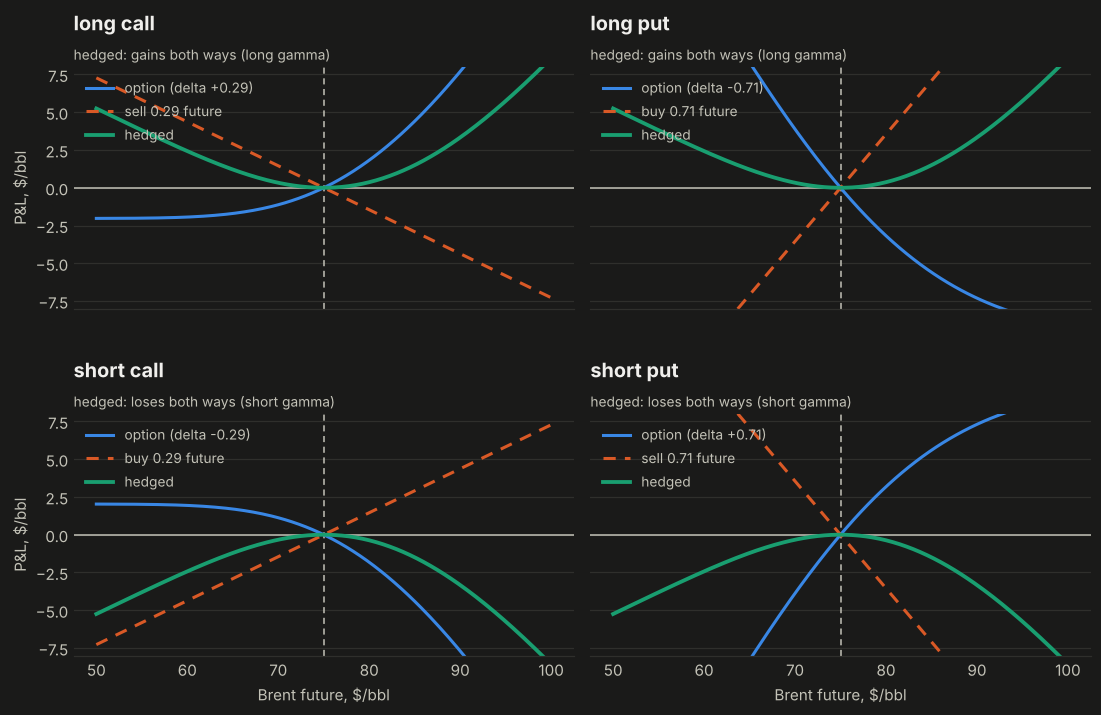

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.6), sharex=True, sharey=True)
for ax, (name, (kind, q)) in zip(axes.flat, positions.items()):
    o = opt(kind, K, q)
    d0 = greeks(o, F0)["delta"]
    pnl_opt = np.array([value(o, f) - value(o, F0) for f in F])
    pnl_fut = -d0 * (F - F0)
    ax.set_axisbelow(True)
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.axvline(F0, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    ax.plot(F, pnl_opt, color=SERIES[0], linewidth=2, label=f"option (delta {d0:+.2f})")
    ax.plot(F, pnl_fut, color=SERIES[1], linewidth=2, linestyle=(0, (4, 3)),
            label=f"{'sell' if d0 > 0 else 'buy'} {abs(d0):.2f} future")
    ax.plot(F, pnl_opt + pnl_fut, color=SERIES[2], linewidth=2.5, label="hedged")
    ax.set(ylim=(-8, 8))
    ax.legend(frameon=False, loc="upper left", fontsize=9)
    titles(ax, name, "hedged: gains both ways (long gamma)" if q > 0
           else "hedged: loses both ways (short gamma)")
for ax in axes[1]:
    ax.set(xlabel="Brent future, $/bbl")
for ax in axes[:, 0]:
    ax.set(ylabel="P&L, $/bbl")
fig.tight_layout(h_pad=2.5)
plt.show()

- At 75 $ the green curve is **flat**: the slopes of the option and of the futures cancel,
  delta = 0.
- Away from 75 the option's slope changes (gamma) and the future's does not, so the green
  curve bends. **Bought**: it goes up both ways. **Sold**: down both ways.
- This is a move right now. As days pass, theta pulls the whole green curve down for a bought
  option (up for a sold one): long gamma wins if the market moves more than the theta it
  pays.

## 7. Why the hedge has to be redone: gamma

After a move the delta is no longer 0, so the futures hedge is reset. The Brent goes
75 → 80 → 75 → 70 → 75, 10,000 bbl of options.

In [11]:
SIZE = 10_000
path = [75.0, 80.0, 75.0, 70.0, 75.0]


def rehedge(o: VanillaOption) -> pd.DataFrame:
    """Reset the futures hedge to delta 0 at each stop of the path."""
    rows, futures, cash = [], 0.0, 0.0
    for f in path:
        g = greeks(o, f)
        trade = -g["delta"] - futures  # futures to trade so that total delta = 0
        cash -= trade * f  # buying costs cash, selling brings cash
        futures += trade
        rows.append({"Brent": f, "option delta": g["delta"], "gamma": g["gamma"],
                     "futures trade": trade, "futures held": futures})
    df = pd.DataFrame(rows)
    df.attrs["futures P&L"] = cash + futures * path[-1]
    return df


lc, sc = rehedge(opt("call", K, +SIZE)), rehedge(opt("call", K, -SIZE))
lc.round(0)

,Brent,option delta,gamma,futures trade,futures held
0,75.0,2910.0,285.0,-2910.0,-2910.0
1,80.0,4408.0,307.0,-1499.0,-4408.0
2,75.0,2910.0,285.0,1499.0,-2910.0
3,70.0,1635.0,219.0,1274.0,-1635.0
4,75.0,2910.0,285.0,-1274.0,-2910.0


Long call, row by row: the Brent rises, the delta rises (gamma > 0), the book is long again →
**sell** futures, at 80. It falls back → **buy** them back, at 75. Same thing below 75. Sell
high, buy low, every time.

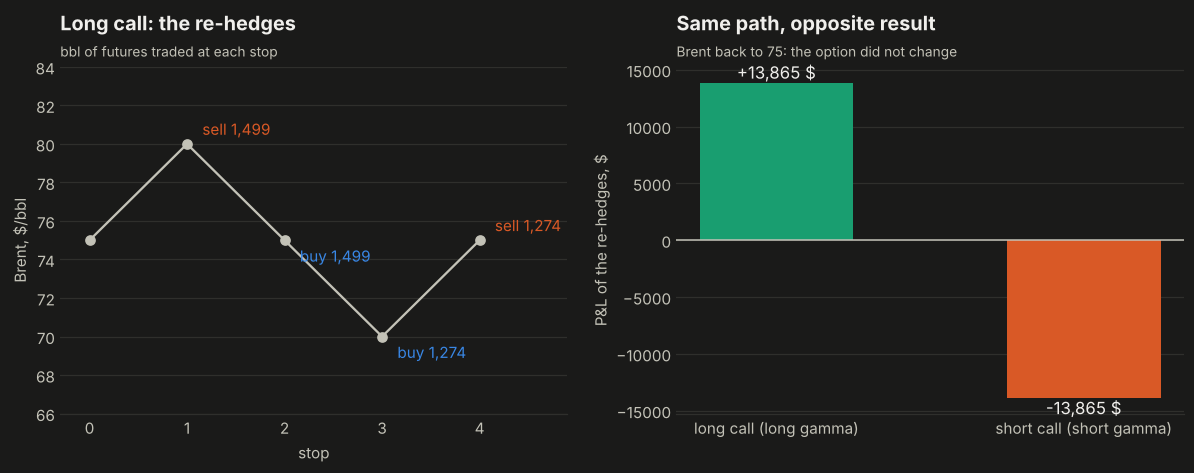

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
ax.set_axisbelow(True)
ax.plot(range(len(path)), path, color=MUTED, linewidth=1.5, marker="o")
for i, row in lc.iterrows():
    if i == 0:
        continue
    side = "sell" if row["futures trade"] < 0 else "buy"
    ax.annotate(f"{side} {abs(row['futures trade']):,.0f}", (i, row["Brent"]),
                xytext=(10, 6 if side == "sell" else -14), textcoords="offset points",
                ha="left", fontsize=10, color=SERIES[1] if side == "sell" else SERIES[0])
ax.set(xticks=range(len(path)), xlabel="stop", ylabel="Brent, $/bbl",
       xlim=(-0.3, 4.9), ylim=(66, 84))
titles(ax, "Long call: the re-hedges", "bbl of futures traded at each stop")

ax = axes[1]
pnl = {"long call (long gamma)": lc.attrs["futures P&L"],
       "short call (short gamma)": sc.attrs["futures P&L"]}
ax.set_axisbelow(True)
ax.bar(list(pnl), list(pnl.values()), color=[SERIES[2], SERIES[1]], width=0.5)
ax.axhline(0, color=MUTED, linewidth=1)
for i, v in enumerate(pnl.values()):
    ax.text(i, v, f"{v:+,.0f} $", ha="center", va="bottom" if v > 0 else "top", fontsize=11)
ax.set(ylabel="P&L of the re-hedges, $")
titles(ax, "Same path, opposite result", "Brent back to 75: the option did not change")
plt.tight_layout()
plt.show()

- **Long gamma** sells high and buys low: it gains when the market moves.
- **Short gamma** buys high and sells low: it loses the same amount.
- No time passes here. In real life the long gamma position pays theta every day for this.

## 8. Removing the gamma: an option first, then futures

To remove the gamma instead of re-hedging it, add the **opposite gamma**, which only an option
has. The long call 83 is hedged with a sold call 75, same expiry:

1. sell enough of the 75 call to cancel the gamma;
2. that trade moves the delta too: reset it with futures.

In [13]:
book = opt("call", K, +SIZE)
g1 = greeks(book, F0)
unit = greeks(opt("call", 75.0), F0)
hedge = opt("call", 75.0, -g1["gamma"] / unit["gamma"])
g2 = greeks(hedge, F0)
fut = -(g1["delta"] + g2["delta"])

pd.DataFrame([
    ["start", "long call 83", g1["delta"], g1["gamma"], g1["vega"], g1["delta"], g1["gamma"]],
    ["1. gamma", f"sell {-hedge.quantity:,.0f} call 75", g2["delta"], g2["gamma"], g2["vega"],
     g1["delta"] + g2["delta"], g1["gamma"] + g2["gamma"]],
    ["2. delta", "futures", fut, 0.0, 0.0, 0.0, g1["gamma"] + g2["gamma"]],
], columns=["step", "trade", "delta", "gamma", "vega", "total delta", "total gamma"]).round(1)

,step,trade,delta,gamma,vega,total delta,total gamma
0,start,long call 83,2909.8,284.5,1290.9,2909.8,284.5
1,1. gamma,"sell 8,622 call 75",-4586.8,-284.5,-1290.9,-1677.0,0.0
2,2. delta,futures,1677.0,0.0,0.0,0.0,0.0


Step 1 brings the gamma to 0 but moves the delta from +2,900 to about −1,700 bbl; step 2 buys
futures. Never the other way round: a future has no gamma. The vega cancels too, exactly:
with the same expiry, gamma and vega are proportional (both ∝ σ√T for a given future price). To keep a vega view, or to hedge gamma and
vega separately, a desk uses two maturities (section 2: short options for gamma, long ones for
vega).

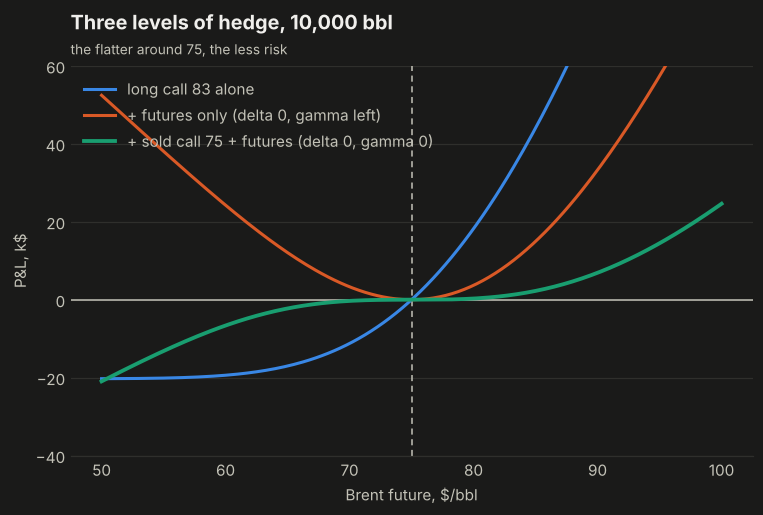

In [14]:
pnl_book = np.array([value(book, f) - value(book, F0) for f in F])
pnl_hedge = np.array([value(hedge, f) - value(hedge, F0) for f in F])

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.set_axisbelow(True)
ax.axhline(0, color=MUTED, linewidth=1)
ax.axvline(F0, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.plot(F, pnl_book / 1e3, color=SERIES[0], linewidth=2, label="long call 83 alone")
ax.plot(F, (pnl_book - g1["delta"] * (F - F0)) / 1e3, color=SERIES[1], linewidth=2,
        label="+ futures only (delta 0, gamma left)")
ax.plot(F, (pnl_book + pnl_hedge + fut * (F - F0)) / 1e3, color=SERIES[2], linewidth=2.5,
        label="+ sold call 75 + futures (delta 0, gamma 0)")
ax.set(xlabel="Brent future, $/bbl", ylabel="P&L, k$", ylim=(-40, 60))
ax.legend(frameon=False, loc="upper left")
titles(ax, "Three levels of hedge, 10,000 bbl", "the flatter around 75, the less risk")
plt.show()

Far from 75 the green curve bends again: the gamma is 0 only at 75 (the two calls have
different strikes), and a large move brings it back.

## 9. In real life: lots of 1,000 bbl

Futures and options on the Brent trade in lots of 1,000 bbl, so the hedge is rounded and a
small delta stays.

In [15]:
LOT = 1_000
pd.DataFrame([
    ["sell call 75 (gamma)", hedge.quantity, round(hedge.quantity / LOT)],
    ["futures (delta)", fut, round(fut / LOT)],
], columns=["trade", "exact, bbl", "lots"]).assign(
    **{"traded, bbl": lambda df: df["lots"] * LOT,
       "left over, bbl": lambda df: df["exact, bbl"] - df["lots"] * LOT}).round(0)

,trade,"exact, bbl",lots,"traded, bbl","left over, bbl"
0,sell call 75 (gamma),-8622.0,-9,-9000,378.0
1,futures (delta),1677.0,2,2000,-323.0


Never exactly 0: a few hundred bbl of delta stay, the rounding residual seen in notebook 06.

## Summary

| Greek | Read on the curve | Hedged with |
|---|---|---|
| Delta | slope | **futures**, opposite sign |
| Gamma | curvature | **options**, opposite gamma (bought ↔ sold), then futures for the delta |
| Vega | gap between vol curves | options, preferably long-dated |
| Theta | gap between dates | not on its own: it comes with gamma |